# Scientific Programming (MSB1015)

# Visualization of Preprocessing Effects and Data Structure

Each session is a different mouse, so neuron identity and repeat identity are not shared between sessions. The only axes common to every mouse are movie time and region label. All plots aside the PARAFAC/TCA plots therefore are built on a shared axis:

- **Sampling coverage**: units per region per session (which mice contribute where)
- **Per-region PSTHs across sessions**: one line per mouse + grand mean, over movie time
- **Unit PSTH embedding (PCA + UMAP)**: every unit represented by its trial-averaged and time-normalized PSTH (a vector over the shared time axis), pooled across mice, colored by region by session (checking for batches).

Cluster-by-region: examine real tuning structure <br>
cluster-by-session: examine batch (mouse/probe) effects

# Imports

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from paths import EXTRACTED_DIR

try:
    import umap
    HAVE_UMAP = True
except Exception:
    HAVE_UMAP = False
    print("umap-learn not found -> UMAP panels skipped. Install with: pip install umap-learn")

try:
    import tensorly as tl
    from tensorly.decomposition import non_negative_parafac
    from tensorly.tenalg import unfolding_dot_khatri_rao
    tl.set_backend("numpy")
    HAVE_TL = True
except Exception:
    HAVE_TL = False
    print("tensorly not installed -> TCA cells skipped. Install with: pip install tensorly")

c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Setup

In [3]:
EMB_BIN = 0.05         # coarse bin (s) for the embedding features
TCA_BIN = 0.10         # 100 ms tensor bins
RANK    = 5            # number of components
UMAP_N_NEIGHBORS = 25  # number of neighbors for the UMAP

REGION_ORDER  = ["VISp", "VISl", "VISal", "VISrl", "VISam", "VISpm"] # visual regions in hierarchical order
REGION_COLORS = {"VISp":"#0072B2","VISl":"#E69F00","VISal":"#009E73",
                 "VISrl":"#D55E00","VISam":"#CC79A7","VISpm":"#56B4E9"} # Okabe-Ito colorblind-safe categorical palette
SEQ = "viridis"

# plotting configuration
plt.rcParams.update({"figure.dpi":110,
                     "axes.spines.top":False,
                     "axes.spines.right":False,
                     "axes.grid":True,
                     "grid.alpha":0.25,
                     "font.size":10})

## Helper functions for loading and pooling the sessions

In [4]:
def list_sessions(extracted_dir=EXTRACTED_DIR):
    """Lists all session files existing in the extracted data directory."""
    return sorted(Path(extracted_dir).glob("session_*.npz"))

def load_session(path):
    """Loads a single session file and returns its contents as a dictionary."""
    session_data = np.load(path, allow_pickle=True)
    return dict(counts=session_data["counts"],
                regions=np.asarray(session_data["regions"]).astype(str),
                bin_size=float(session_data["bin_size"]),
                session_id=int(session_data["session_id"]))

def rebin_sum(x, factor):
    """
    Rebins a 2D array by summing over non-overlapping windows of size factor
    along the first axis.
    """
    row_count = (x.shape[0] // factor) * factor
    return x[:row_count].reshape(row_count // factor, factor, x.shape[1]).sum(1)

def gsmooth(x, sigma):
    """Smooths a 1D array with a Gaussian kernel of standard deviation sigma."""
    if sigma <= 0: return x # checks for nonsensical sigma values

    r = int(np.ceil(3*sigma))
    k = np.exp(-0.5*(np.arange(-r, r+1)/sigma)**2)
    k /= k.sum()

    return np.convolve(x, k, mode="same")

# Execute Pooling

In [5]:
sessions   = list_sessions()  # lists all sessions
assert sessions, f"No session_*.npz-file found in the directory {EXTRACTED_DIR.resolve()}"
count_mat  = []                                  # session x region unit counts
region_psth= {r: [] for r in REGION_ORDER}       # region -> [(sid, psth_Hz or None), ...]

U_list, unit_regions, unit_sessions, session_id_list = [], [], [], []
bin_size_0 = load_session(sessions[0])["bin_size"] if sessions else 0.01 # extracts first bin size (s) for plotting time axis

# loops over all sessions
for session_path in sessions:
    data = load_session(session_path) # loads a single session
    # extracts session-wise data
    session_id = data["session_id"] # session id list
    bin_size = data["bin_size"]
    regions = data["regions"]
    # counts is shaped like [trial, time_bin, unit], averaging over axis 0 yields [time_bin, unit] mean spikes/bin -> the mean spike count at each time point for each neuron.
    trial_avg_activity = data["counts"].mean(0)  # average activity per trial (PSTH)

    session_id_list.append(session_id) # store session id in session iod list

    count_mat.append([int((regions == region).sum()) for region in REGION_ORDER]) # stores the number of units in each regions for every sessions

    # computes the per-region population PSTH in Hz (fine + smoothed)
    for region in REGION_ORDER:
        mask = regions == region  # Boolean mask created by comparing every unit’s region
        region_psth[region].append((session_id, gsmooth(trial_avg_activity[:, mask].mean(1)/bin_size, 3) if mask.sum() else None))

    # pooled per-unit PSTH for embedding: rebinning to coarser bins for reduction of time features for PCA & UMAP, z-scored across time
    factor = max(1, int(round(EMB_BIN/bin_size))) # factor for coarser time bins, reduces small, noisy fluctuations in individual fine bins
    coarse = rebin_sum(trial_avg_activity, factor) / (bin_size*factor)  # rebinning into coarser time bins of [Tc, unit] Hz
    z = (coarse - coarse.mean(0)) / (coarse.std(0) + 1e-9)  # r-scores each unit across time (focus on response shape)

    U_list.append(z.T)  # [number_of_units, number_coarse_time_bins]
    unit_regions.append(regions)
    unit_sessions.append(np.full(len(regions), session_id))


count_df = pd.DataFrame(count_mat, index=session_id_list, columns=REGION_ORDER)

Time_bins_coarse = min(a.shape[1] for a in U_list)
U = np.vstack([a[:, :Time_bins_coarse] for a in U_list])  # [N_units, Time_bins_coarse]
unit_regions  = np.concatenate(unit_regions)   # each unit's brain-region lavel
unit_sessions = np.concatenate(unit_sessions)  # each unit's session

print(f"{len(sessions)} sessions | pooled units: {U.shape[0]} | time features: {U.shape[1]}")
print(f"Total units per region: " + ", ".join(f"{region}={int((unit_regions==region).sum())}" for region in REGION_ORDER))

32 sessions | pooled units: 5329 | time features: 600
Total units per region: VISp=1299, VISl=533, VISal=1004, VISrl=902, VISam=1019, VISpm=572


## 1. Sampling coverage in units per region per session
Illustrates the amount of units each mouse (1 mouse per 1 session) contributes to an area. Blank cells mean a probe missed that area. <br>
Each region's pooled statistics come from a *different subset of mice* (a built-in batch confound).

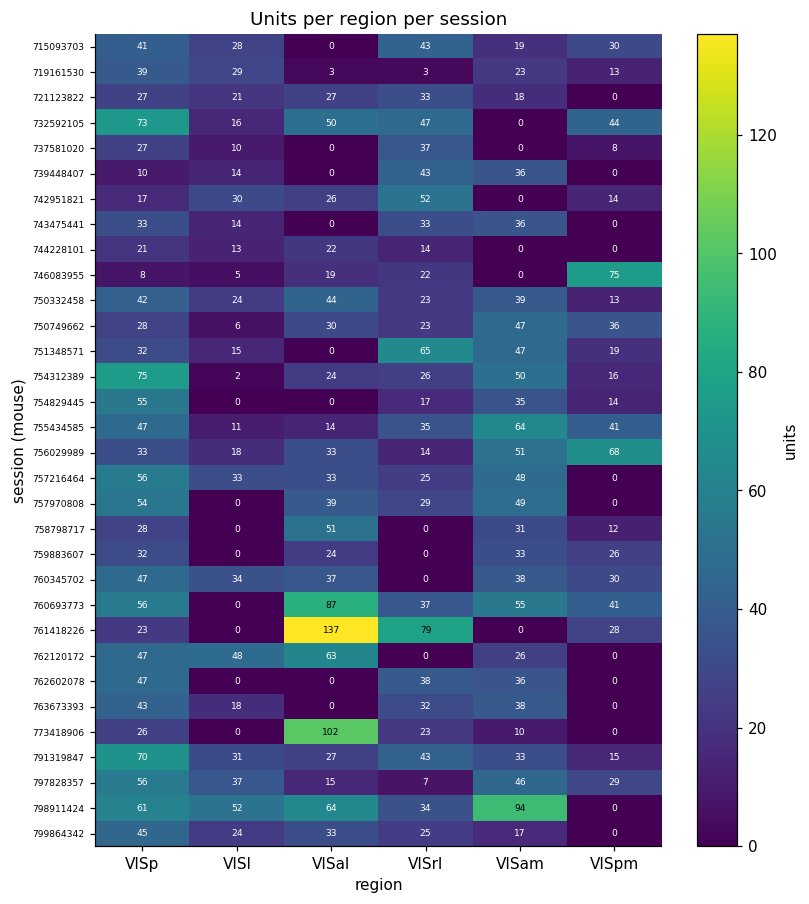

In [6]:
fig, ax = plt.subplots(figsize=(7.5, max(4, 0.26*len(count_df))))
vals = count_df.values # yields the per-region per-session counts (each cell is the unit count)
thresh = vals.max() * 0.55
im = ax.imshow(vals, aspect="auto", cmap=SEQ)

# Regions
ax.set_xticks(range(len(REGION_ORDER)))
ax.set_xticklabels(REGION_ORDER) # region labels
# Sessions
ax.set_yticks(range(len(count_df)))
ax.set_yticklabels(count_df.index, fontsize=6) # session labels

# iterates over all regions and sessions
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        ax.text(j, i, int(vals[i, j]), ha="center", va="center", fontsize=6,
                color="white" if vals[i, j] < thresh else "black")
        
ax.set_xlabel("region")
ax.set_ylabel("session (mouse)")
ax.set_title("Units per region per session")

plt.colorbar(im, label="units")
ax.grid(False)

plt.tight_layout()
plt.show()

## 2. Per-region population PSTH across sessions
For each area
- **thin line**: one trial-averaged population rate of a mouse over movie time
- **thick line**: grand mean across mice. <br>
**overlapping thin lines**: indicate that the average firing rates are similar in a particular brain region for two/multiple mice. <br>
Wide scatter indicates strong between-mouse (possibly a batch effect but also inter-individual) variability for that area.

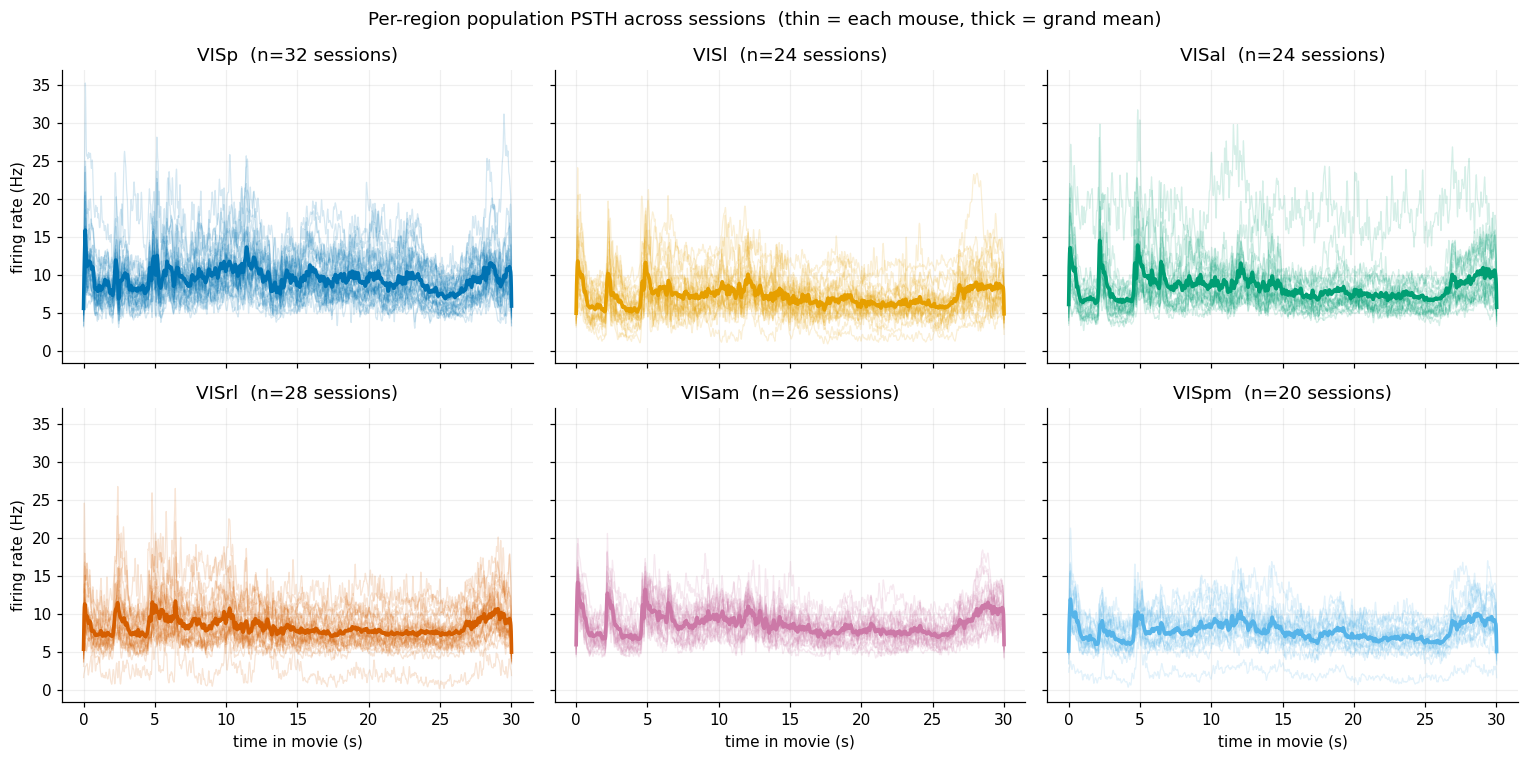

In [7]:
# extracts lengths of all available regional PSTHs
valid_lens = [len(ps) for r in REGION_ORDER for _, ps in region_psth[r] if ps is not None]
number_fine_time_bins = min(valid_lens) # number of fine time bins used for plotting (minimum ensures every plotted PSTH had enough data, even sessions/regions with PSTHs of different lengths) 
fine_time_bins_axis = np.arange(number_fine_time_bins) * bin_size_0 # (arange creates bin indices, bin_size_0 converts them into seconds)

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)

for ax, region in zip(axes.ravel(), REGION_ORDER):
    stack = []
    for session_id, psth in region_psth[region]:
        if psth is None: continue  # skips over missing psths
        psth = psth[:number_fine_time_bins]
        stack.append(psth)
        ax.plot(fine_time_bins_axis, psth, color=REGION_COLORS[region], alpha=0.16, lw=0.8)
    if stack:
        ax.plot(fine_time_bins_axis, np.vstack(stack).mean(0), color=REGION_COLORS[region], lw=2.4)
    ax.set_title(f"{region}  (n={len(stack)} sessions)")
    ax.grid(alpha=0.2)

# set time axis labels
for ax in axes[-1]: ax.set_xlabel("time in movie (s)")
# set firing rate axis labels
for ax in axes[:, 0]: ax.set_ylabel("firing rate (Hz)")
# figure title
fig.suptitle("Per-region population PSTH across sessions  (thin = each mouse, thick = grand mean)")

plt.tight_layout()
plt.show()

## 3. Unit PSTH embedding: PCA & UMAP
Each unit is represented by its trial-averaged PSTH over the shared movie-time axis and z-scored across time. The z-scoring yields the temporal shape of the signal only, not the absolute firing rate. Features are PCA-reduced to 50 dims, then embedded. 
- **Left Panel**: colored by region, answer the question "Do areas occupy a distinct response space?"
- **Right Panel**: colored by session, if points group by color here, batch  effects(mouse/probe) are driving the structure rather than region.

PCA: first 2 PCs explain 13.5% of PSTH-shape variance
First 50 PCs explain 58.7%


c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


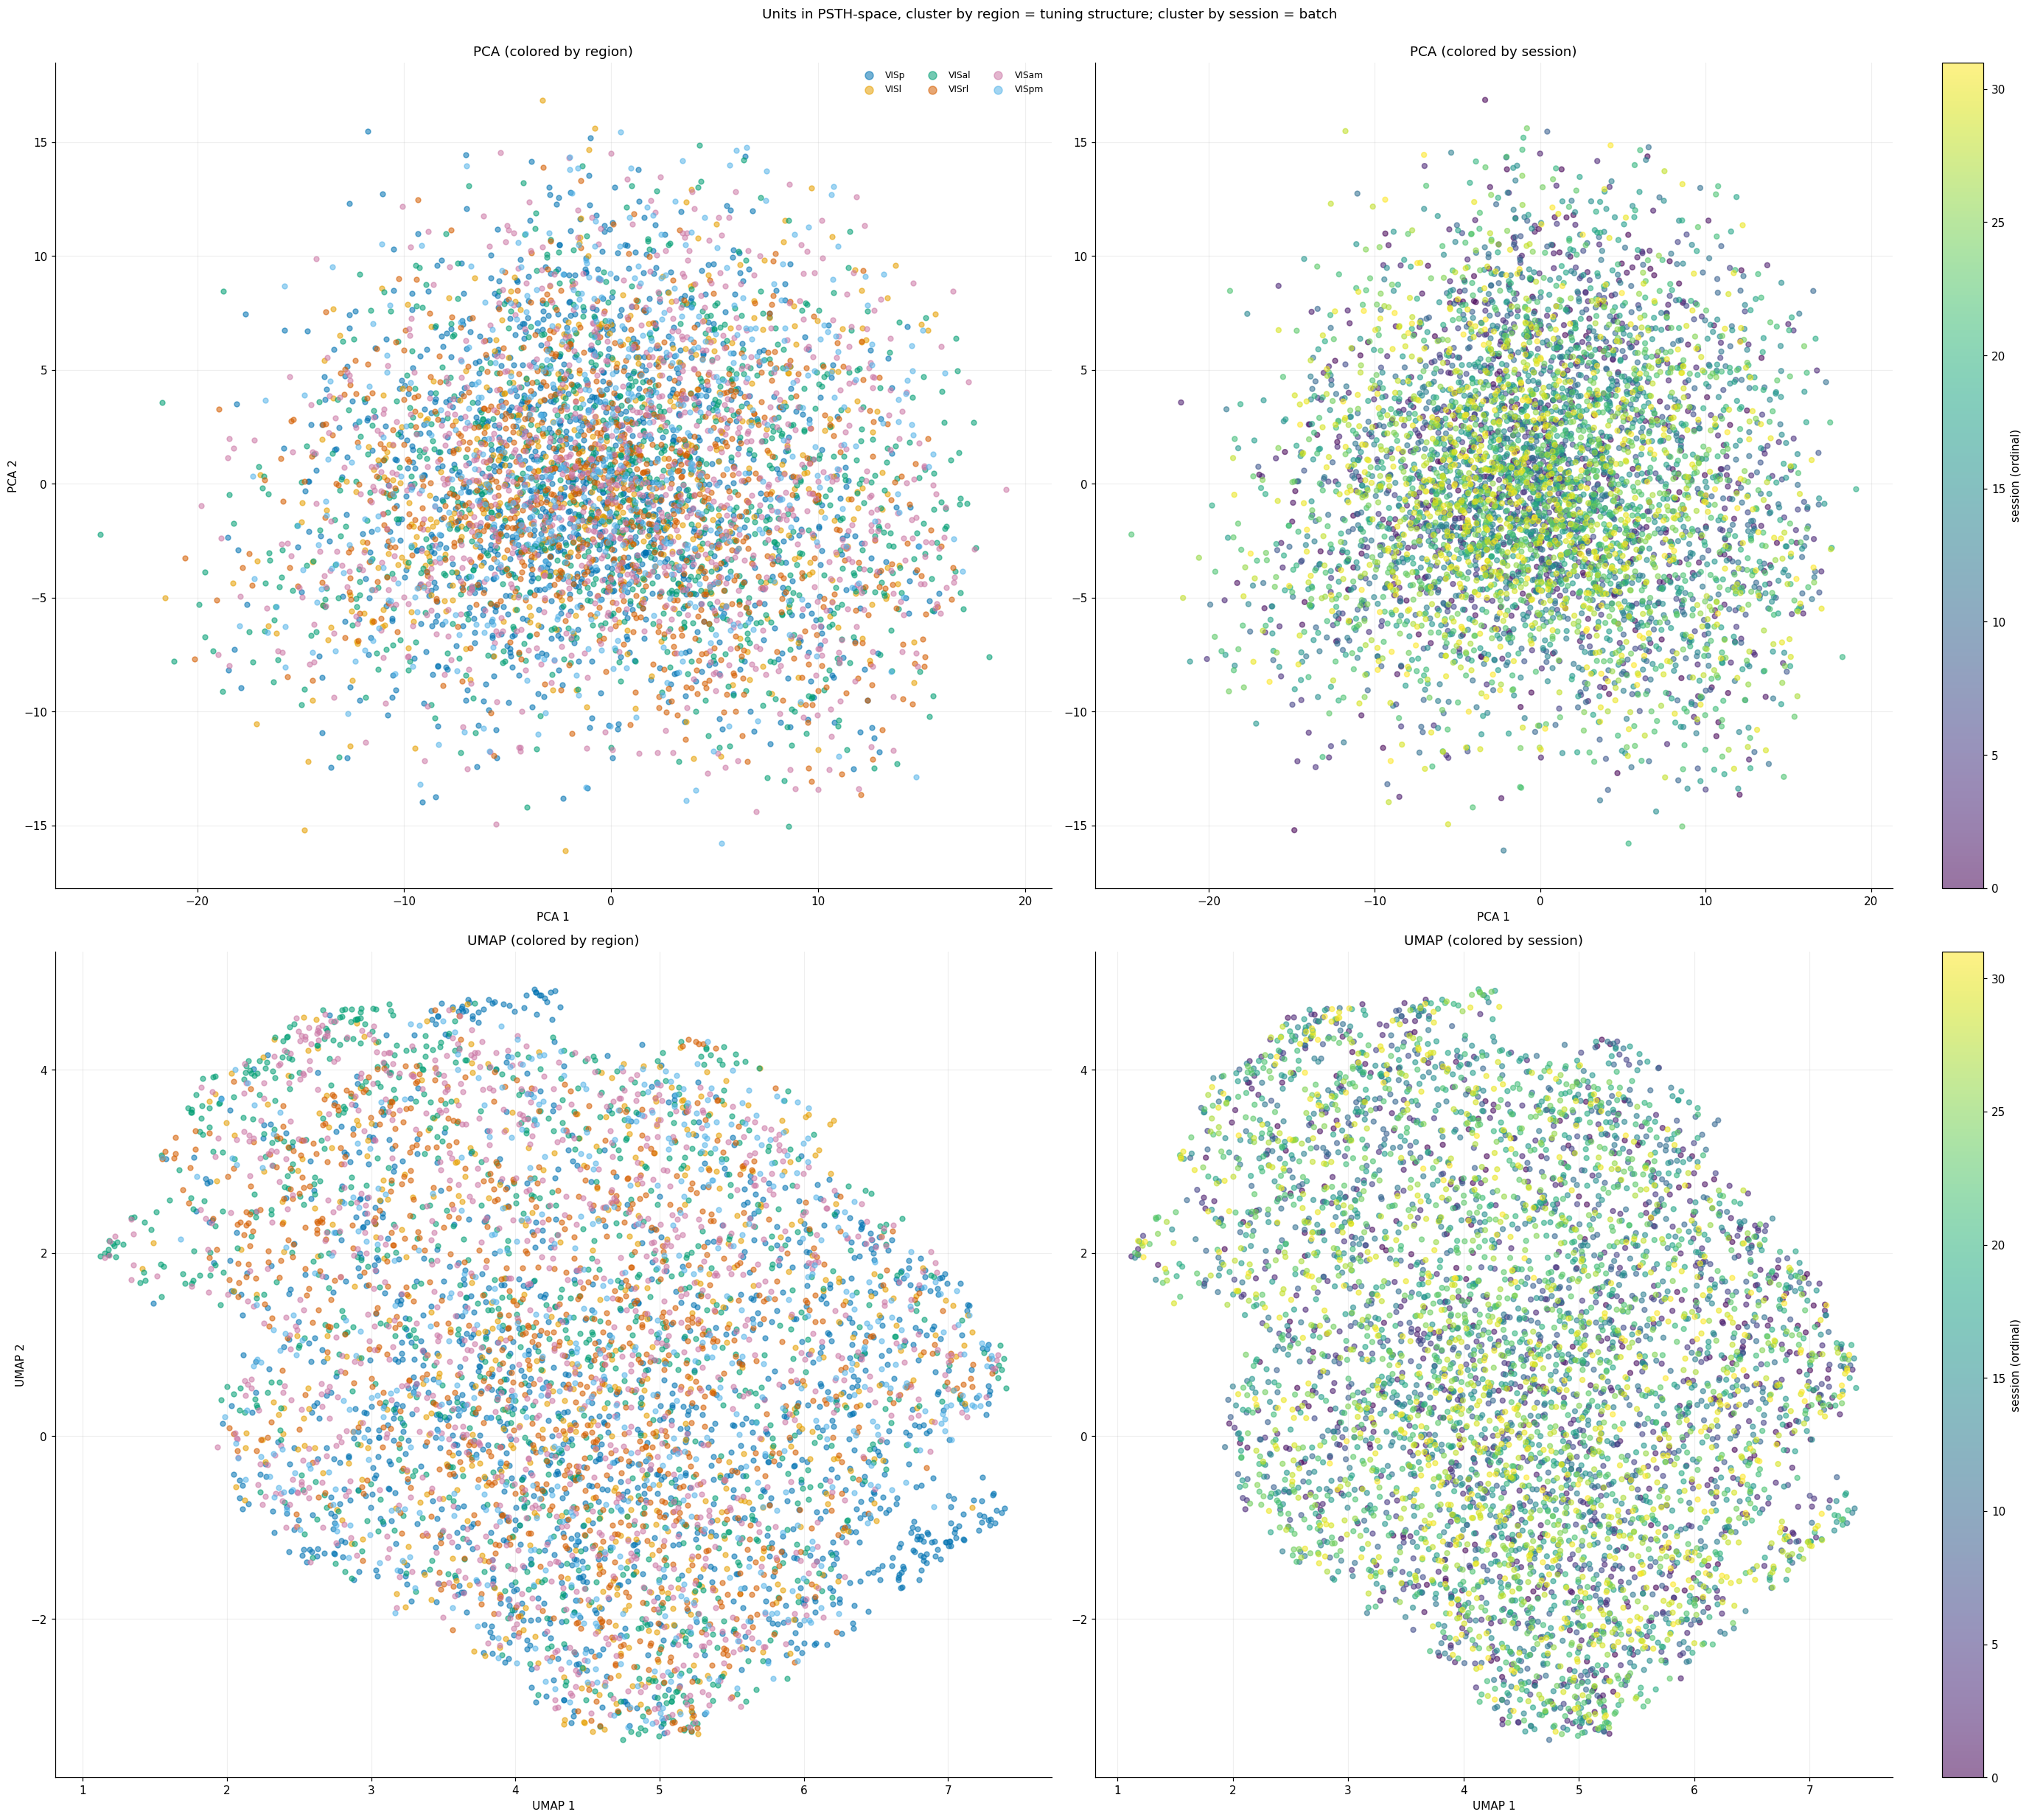

In [8]:
# Perform PCA
n_pc = int(min(50, U.shape[1], U.shape[0] - 1))
pca  = PCA(n_components=n_pc, random_state=0).fit(U)  # performs PCA with n_pc components 
Z    = pca.transform(U)  # projects U onto the first principal components

# prints how much variance is explained
print(f"PCA: first 2 PCs explain {100*pca.explained_variance_ratio_[:2].sum():.1f}% "
      f"of PSTH-shape variance\nFirst {n_pc} PCs explain "
      f"{100*pca.explained_variance_ratio_.sum():.1f}%")

# keeps the first 2 PCs for plotting where Z[:, 0] = PCA coordinate 1 and Z[:, 1] = PCA coordinate 2
PC_X, PC_Y = 0, 1
embeddings = {"PCA": Z[:, [PC_X, PC_Y]]}

if HAVE_UMAP:
    embeddings["UMAP"] = umap.UMAP(n_neighbors=UMAP_N_NEIGHBORS, # default 15-50, larger = more global structure, smaller = more local structure 
                                  min_dist=0.15,
                                  random_state=0).fit_transform(Z)

# # converts session ids into color indices
session_idx_dict = {s: i for i, s in enumerate(sorted(set(unit_sessions.tolist())))}
session_idx = np.array([session_idx_dict[session] for session in unit_sessions])

n_rows = len(embeddings) # first row PCA, second UMAP

# creates a 2D map where each dot represents one neuron (unit)
fig, axes = plt.subplots(n_rows, 2, figsize=(26, 11.2*n_rows), squeeze=False)

# loops over PCA and UMAP results and plots them
for i, (name, XY) in enumerate(embeddings.items()):
    axr = axes[i, 0]
    for region in REGION_ORDER:
        mask = unit_regions == region  # boolean mask to cselect neurons by region
        # colors and labels neurons by region, XY[m, 0] and XY[m, 1] selects the x- and y-coords of only these neurons
        axr.scatter(XY[mask, 0], XY[mask, 1], s=20, c=REGION_COLORS[region], label=region, alpha=0.55, linewidths=1)

    # set title and labels
    axr.set_title(f"{name} (colored by region)")
    axr.set_xlabel(f"{name} 1")
    axr.set_ylabel(f"{name} 2")

    if i == 0: axr.legend(ncol=3, frameon=False, fontsize=8, markerscale=1.6)
    axr.grid(alpha=0.2)
    axs = axes[i, 1]
    sc = axs.scatter(XY[:, 0], XY[:, 1], s=20, c=session_idx, cmap=SEQ, alpha=0.55, linewidths=1)
    axs.set_title(f"{name} (colored by session)")
    axs.set_xlabel(f"{name} 1")
    plt.colorbar(sc, ax=axs, label="session (ordinal)")
    axs.grid(alpha=0.2)

fig.suptitle("Units in PSTH-space, cluster by region = tuning structure; cluster by session = batch", y=1.0)

plt.tight_layout()
plt.show()

## 4. Tensor decomposition (PARAFAC / TCA)

Each session is essentially a 3rd-order tensor `[neuron × time × trial]` (Williams et al., *Neuron* 2018 Tensor Components Analysis). <br>
A rank-R non-negative CP/PARAFAC factorizes it into R components, with each component representing the product of a **temporal factor** (× movie time), a **neuron factor** (which cells load on it), and a **trial factor** (how it's modulated across repeats).

- **4a**: runs per-session TCA on one example session (interpretable single-mouse decomposition).
- **4b**: fits a **coupled** decomposition across all sessions with a shared temporal factor. <br>
The time mode is the only axis common to every mouse, meaning it can be evaluated across sessions while neuron and trial factors stay session-specific. That is the principled way to pull out cohort-wide temporal motifs without ever pooling raw activity across mice. <br>
Tensors are binned to 100 ms, √-transformed (variance-stabilizes Poisson counts, keeps ≥ 0), and soft-normalized per neuron so units with high firing rates don't dominate.

In [9]:
if HAVE_TL:
    def rebin_parafac(counts, factor):
        num_rows = (counts.shape[1] // factor) * factor
        return counts[:, :num_rows].reshape(counts.shape[0], num_rows // factor, factor, counts.shape[2]).sum(2)

    def session_tensor(data, time_bin=TCA_BIN):
        factor = max(1, int(round(time_bin / data["bin_size"])))
        counts = rebin_parafac(data["counts"], factor)      # [rep, Tc, unit]
        X = np.transpose(counts, (2, 1, 0)).astype(float)   # [unit, Tc, rep]
        X = np.sqrt(X)                                      # variance-stabilization, stays >= 0
        X = X / (X.max(axis=(1, 2), keepdims=True) + 1e-3)  # soft per-neuron normalization
        return X

    tensors, regions_list, session_ids = [], [], []
    for session_path in sessions:
        session_data = load_session(session_path)
        tensors.append(session_tensor(session_data))
        regions_list.append(session_data["regions"])
        session_ids.append(session_data["session_id"])
    
    time_bins_len = min(X.shape[1] for X in tensors)  # common time length
    tensors = [X[:, :time_bins_len, :] for X in tensors]
    time_axis = np.arange(time_bins_len) * TCA_BIN

    print(f"{len(tensors)} session tensors | shared time bins: {time_bins_len} | example shape {tensors[0].shape} (unit, time, trial)")

32 session tensors | shared time bins: 300 | example shape (161, 300, 20) (unit, time, trial)


### 4a. Per-session TCA (one example session)

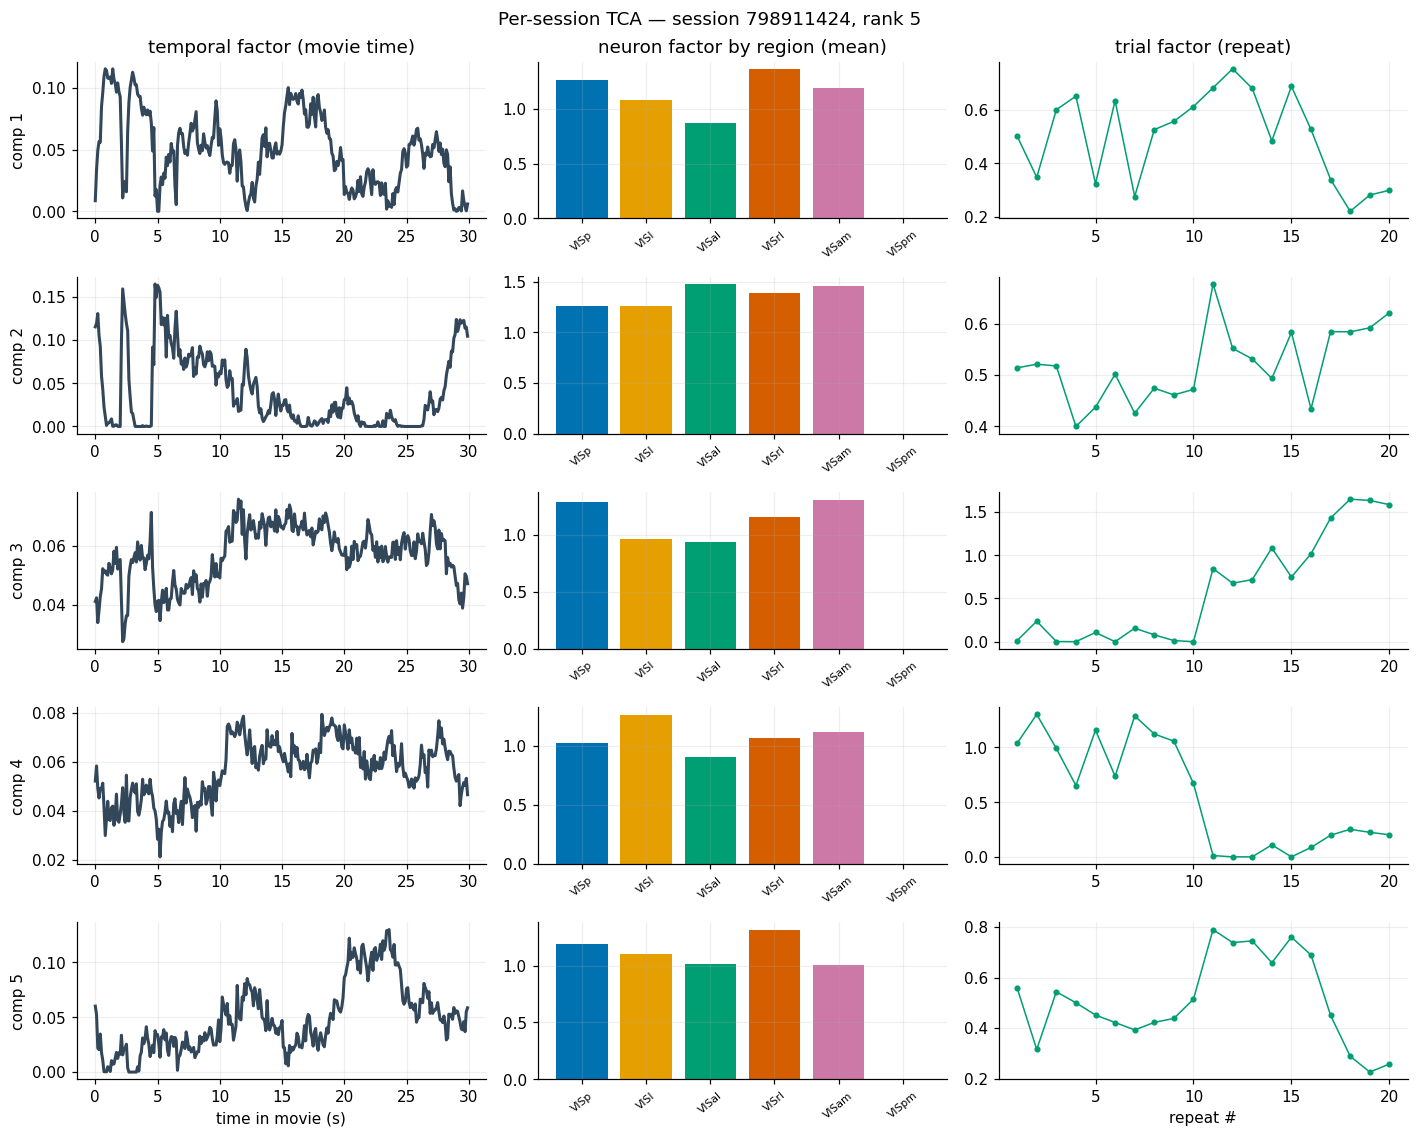

In [10]:
if HAVE_TL:
    best_id = int(count_df.sum(1).idxmax())  # session with the largest total unit count
    best_data = load_session(EXTRACTED_DIR / f"session_{best_id}.npz")  # loads data from the session with best_id
    best_data_trimmed  = session_tensor(best_data)[:, :time_bins_len, :]  # best_id session trimmed
    region_best = best_data["regions"]  # brain region lavels for each unit, aligned with 1st axis of best_data_trimmed

    w, (A, B, C) = non_negative_parafac(tl.tensor(best_data_trimmed), rank=RANK, init="random",
                                        n_iter_max=300, tol=1e-7, random_state=0)
    A, B, C = np.array(A), np.array(B), np.array(C)  # ABC are the 3 factors PARAFAC decomposes the tensor into
    
    for rank in range(RANK):                     # unit-norm temporal factor, scale -> neuron factor
        normalized_scale = np.linalg.norm(B[:, rank]) + 1e-9
        B[:, rank] /= normalized_scale  # normalizes temporal profile in B to have length of approx. 1
        A[:, rank] *= normalized_scale  # apply normalization to A
    ordered_components = np.argsort(B.argmax(0))     # orders components by their temporal peak

    fig, axes = plt.subplots(RANK, 3, figsize=(13, 2.1*RANK), squeeze=False)

    # iterates over ordered factorization components
    for i, comp in enumerate(ordered_components):
        axes[i, 0].plot(time_axis, B[:, comp], color="#33475B", lw=2)  # shows the component’s temporal profile across time_axis
        axes[i, 0].set_ylabel(f"comp {i+1}")

        # calculates the average A weight for the component among units in each brain region
        vals = [A[region_best == region, comp].mean() if (region_best == region).any() else 0.0 for region in REGION_ORDER]
        
        axes[i, 1].bar(range(len(REGION_ORDER)), vals, color=[REGION_COLORS[x] for x in REGION_ORDER])
        axes[i, 1].set_xticks(range(len(REGION_ORDER)))
        axes[i, 1].set_xticklabels(REGION_ORDER, fontsize=7, rotation=40)
        # shows the component’s values across repeats, with repeat numbers along the x-axis
        axes[i, 2].plot(range(1, C.shape[0]+1), C[:, comp], color="#009E73", marker="o", ms=3, lw=1)
        
        for a in axes[i]: a.grid(alpha=0.2)

    axes[0, 0].set_title("temporal factor (movie time)")
    axes[0, 1].set_title("neuron factor by region (mean)")
    axes[0, 2].set_title("trial factor (repeat)")
    axes[-1, 0].set_xlabel("time in movie (s)")
    axes[-1, 2].set_xlabel("repeat #")
    fig.suptitle(f"Per-session TCA — session {best_id}, rank {RANK}")

    plt.tight_layout()
    plt.show()

### 4b Coupled TCA: shared temporal factor across sessions
One temporal basis `B` (movie time) is shared by every mouse; each session keeps its own neuron
loadings `A_s` and trial loadings `C_s`. Fit by projected coupled CP-ALS (non-negative). Left: the
shared temporal components; right: how each component's neuron loading distributes across regions,
pooled over all mice (row-normalized).

coupled CP relative reconstruction error (every 10 iters): [0.65, 0.629, 0.628, 0.628, 0.627, 0.627, 0.627, 0.626, 0.626]


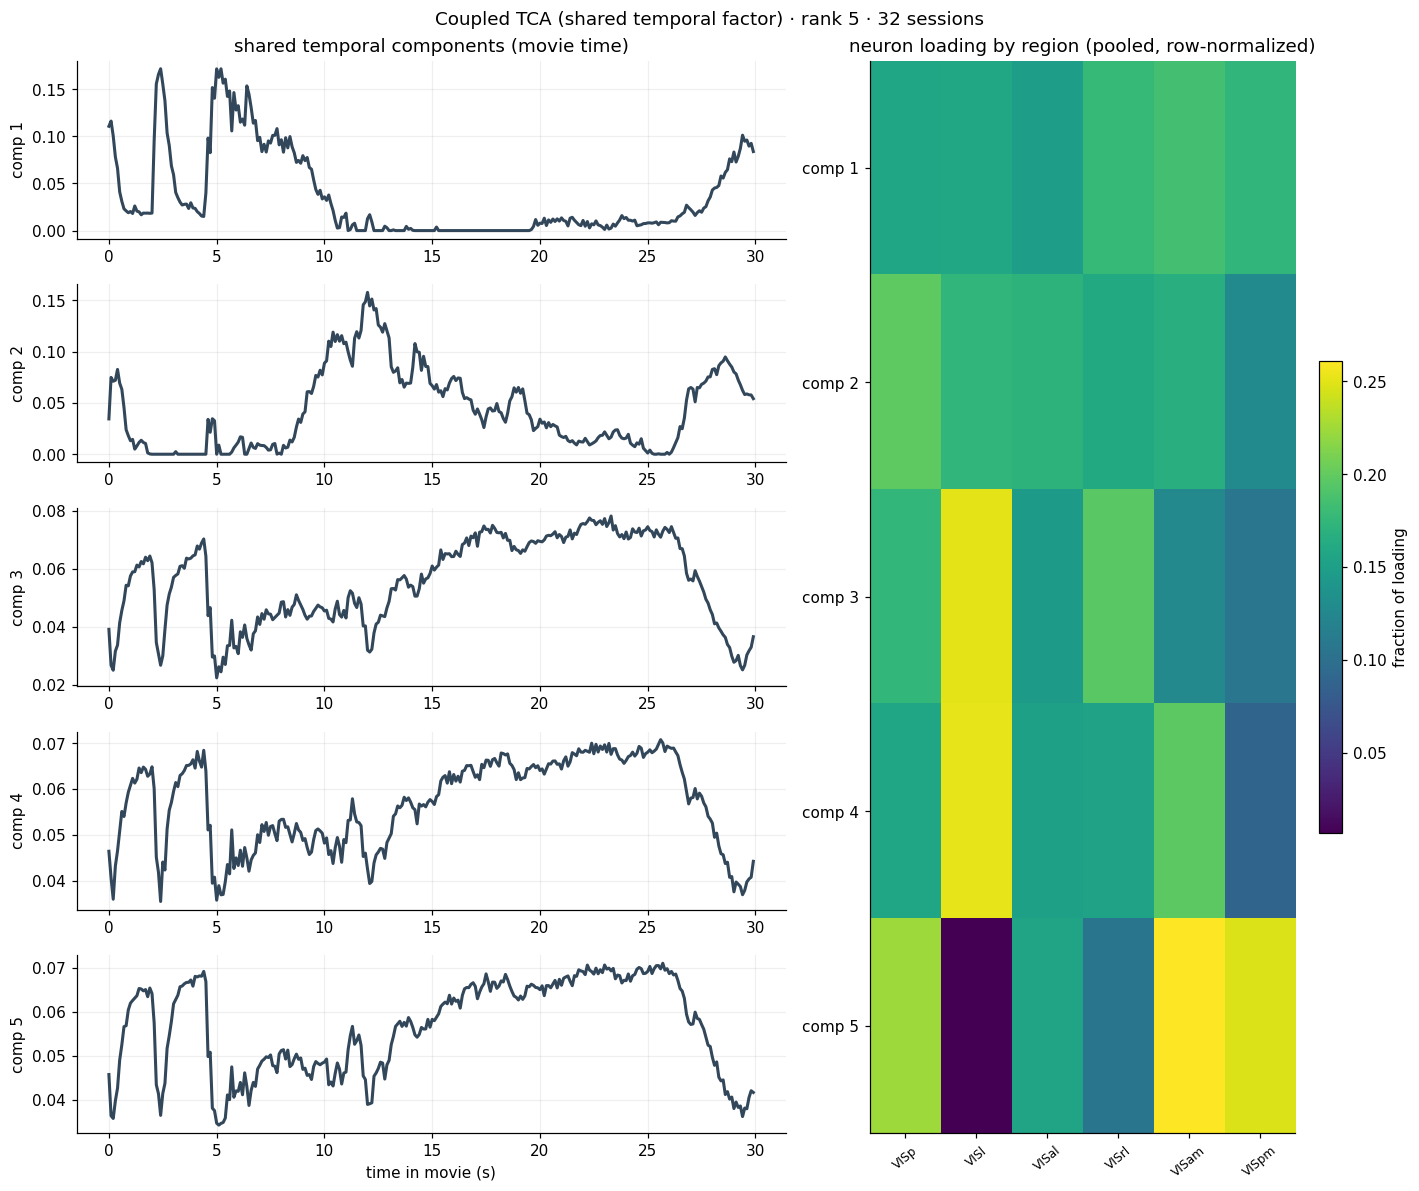

In [11]:
if HAVE_TL:
    def _gram(Fac_matrices, rank):
        """
        Computes a rank x rank matrix multiplying the gram matrices of the factor matrices.
        Gram matrix: contains pairwise similarities between the factor columns
        """
        G = np.ones((rank, rank))
        for F in Fac_matrices: G = G * (F.T @ F)
        return G

    def coupled_cp(tensors, rank, n_iter=80, seed=0, nonneg=True):
        """
        Fits a PARAFAC (coupled cp) decomposition to multiple 3D session tensors.
        Learns for each session:
        - shared time factor B
        - separate unit factors A
        - repeat factors C
        The factors are updated iteratively, optionally clipped (to nonneg. values)
        and the relative reconstructione error is recorded.
        """
        rng = np.random.default_rng(seed)  # random number generator with specified seed
        T = tensors[0].shape[1]            # number of time bins
        Bs = rng.random((T, rank))         # starts as random values with (time bins, components)
        As = [rng.random((X.shape[0], rank)) for X in tensors]  # list with one random unit-factor matrix per session where each of them has shape (units in that session, components)
        Cs = [rng.random((X.shape[2], rank)) for X in tensors]  # list with one random repeat-factor matrix per session where each has shape (repeats in that session, components)

        clip = (lambda M: np.maximum(M, 0.0)) if nonneg else (lambda M: M)
        w = np.ones(rank)  # weight matrix with one weight per component
        recon_errors = []  # reconstruction errors

        # repeats the factor updates n_iter times
        for it in range(n_iter):
            for session_id, session_data in enumerate(tensors):
                # updates the session's unit factors
                As[session_id] = clip(unfolding_dot_khatri_rao(session_data, (w, [As[session_id], Bs, Cs[session_id]]), 0) @ np.linalg.pinv(_gram([Bs, Cs[session_id]], rank)))
                # updates the session's repeat factors
                Cs[session_id] = clip(unfolding_dot_khatri_rao(session_data, (w, [As[session_id], Bs, Cs[session_id]]), 2) @ np.linalg.pinv(_gram([As[session_id], Bs], rank)))
            
            num = np.zeros((T, rank))  # accumulator for time-mode tensor products of all sessions
            ls_matrices = np.zeros((rank, rank)) # accumulator for corresponding least-squares matrices from all sessions

            for session_id, session_data in enumerate(tensors):
                num += unfolding_dot_khatri_rao(session_data, (w, [As[session_id], Bs, Cs[session_id]]), 1)
                ls_matrices += _gram([As[session_id], Cs[session_id]], rank)
            Bs = clip(num @ np.linalg.pinv(ls_matrices))

            if it % 10 == 0 or it == n_iter - 1:
                sse = tot = 0.0
                for session_id, session_data in enumerate(tensors):
                    recon_session = tl.cp_to_tensor((w, [As[session_id], Bs, Cs[session_id]]))
                    sse += np.sum((session_data - recon_session)**2)  # accumulates squared diff between original data and reconstruction
                    tot += np.sum(session_data**2)  # accumulates squared size of the original data
                recon_errors.append(float(np.sqrt(sse / tot)))  # appends relative reconstruction error across sessions
        return Bs, As, Cs, recon_errors

    #  returns the shared time factors, the per-session unit factors, the per-session repeat factors and the recorded errors
    Bsh, A_list, C_list, recon_errors = coupled_cp(tensors, RANK, n_iter=80, seed=0)
    print("coupled CP relative reconstruction error (every 10 iters):", [round(e, 3) for e in recon_errors])

    # normalizes and orders the shared time profiles
    for rank in range(RANK):
        Bsh[:, rank] /= (np.linalg.norm(Bsh[:, rank]) + 1e-9)
    order = np.argsort(Bsh.argmax(0))  # lists component indices from earliest peak to latest

    # yields component-wise pooled neuron loading by region
    comp_region = np.zeros((RANK, len(REGION_ORDER)))
    for comp_idx, comp_loading in enumerate(order):
        for region_idx, region in enumerate(REGION_ORDER):
            session_arys = [A_list[s][regions_list[s] == region, comp_loading] for s in range(len(tensors)) if (regions_list[s] == region).any()]
            comp_region[comp_idx, region_idx] = np.concatenate(session_arys).mean() if session_arys else 0.0
    comp_region_n = comp_region / (comp_region.sum(1, keepdims=True) + 1e-9)  # normalization

    fig = plt.figure(figsize=(13, 2.0*RANK + 1))
    gs = fig.add_gridspec(RANK, 2, width_ratios=[1.5, 1])

    for i, r in enumerate(order):
        ax = fig.add_subplot(gs[i, 0])
        ax.plot(time_axis, Bsh[:, r], color="#33475B", lw=2)
        ax.set_ylabel(f"comp {i+1}")
        ax.grid(alpha=0.2)
        if i == 0: ax.set_title("shared temporal components (movie time)")
        if i == RANK - 1: ax.set_xlabel("time in movie (s)")
    
    axh = fig.add_subplot(gs[:, 1])
    im = axh.imshow(comp_region_n, aspect="auto", cmap=SEQ)
    axh.set_xticks(range(len(REGION_ORDER)))
    axh.set_xticklabels(REGION_ORDER, rotation=40, fontsize=8)
    axh.set_yticks(range(RANK))
    axh.set_yticklabels([f"comp {i+1}" for i in range(RANK)])
    axh.set_title("neuron loading by region (pooled, row-normalized)")
    
    plt.colorbar(im, ax=axh, fraction=0.05, label="fraction of loading")
    axh.grid(False)
    fig.suptitle(f"Coupled TCA (shared temporal factor) · rank {RANK} · {len(tensors)} sessions")
    
    plt.tight_layout()
    plt.show()

## Notes
- These axes are valid across mice because every view is indexed by movie time or region, which are the only axes shared across sessions. Pooling raw `[trials × units]` activity across mice into one matrix (neuron *i* differs between animals) should never be done
- **PSTH z-scoring** captures response *shape* because without it, PC1 would likely just capture the firing rate magnitude (making it a scale/batch axis). For a rate-magnitude view, the z-score could be dropped
- **UMAP** distorts global geometry so it adds to PCA, and doesn't replace it

## TCA notes

- **Rank & runtime:** `RANK` is the number of components; the reconstruction error and interpretability might vary by varying the number of components. The coupled fit is a projected (non-negative) CP-ALS from random init. Rerunning it with different `seed`s should yield a stable solution; CP is unique up to permutation/scaling but not immune to local minima
- **Preprocessing:** dropping √-transform and per-neuron soft-normalization makes components track raw rate and a few loud neurons
- **Per-session vs coupled.** Per-session TCA components are only comparable across mice *after* matching, as they're permuted/scaled independently. The coupled fit sidesteps that by construction. The temporal components are shared, so `comp k` means the same thing in every mouse, and the region heatmap is directly interpretable.